# 01 · Kết quả tìm kiếm (Alpha-Beta vs MCTS)

Notebook đọc **log thô JSONL** trong `logs/` và dựng lại toàn bộ số liệu, hình của phần đánh giá:

| Mục | Nội dung |
|---|---|
| 1 | Ma trận Win Score kèm khoảng tin cậy Wilson 95% (chế độ 1 và chế độ 2) |
| 2 | Thắng / hòa / thua theo từng cặp |
| 3 | Độ trễ trung bình và p95 **theo từng nước** |
| 4 | Nút/giây (Alpha-Beta) và mô phỏng/giây (MCTS) |
| 5 | Tỷ lệ khi đi trước so với đi sau |
| 6 | RQ1: Alpha-Beta vs MCTS ở 200 ms và 1000 ms |
| 7 | Ablation A1 (cắt tỉa / sắp xếp nước) |
| 8 | Ablation A2 (MCTS: `n_simulations` × `c`) |
| 9 | Xuất bảng tóm tắt `logs/summary_*.csv` |

Chạy lại: sửa các đường dẫn ở ô cấu hình bên dưới rồi **Run All**. Hình lưu vào `results/figures/`.

In [29]:
from pathlib import Path
import json, math
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

# ── Cấu hình đường dẫn ─────────────────────────────────────────────────────────
ROOT = Path.cwd()

if ROOT.name == "eval":
    BASE_DIR = ROOT.parent
else:
    BASE_DIR = ROOT

LOG_DIR = BASE_DIR / "logs"
FIG_DIR = BASE_DIR / "results" / "figures"

FIG_DIR.mkdir(parents=True, exist_ok=True)

TOURNAMENTS = {
    "tournament": LOG_DIR / "tournament_games.jsonl",
}

RQ1_LOGS = [LOG_DIR / "rq1_200ms_games.jsonl", LOG_DIR / "rq1_1000ms_games.jsonl"]
ABLATION_LOG = LOG_DIR / "ablation.jsonl"

SAVE_FIGS = True

## Hàm dùng chung

In [30]:
def wilson_ci(wins: float, n: int, z: float = 1.96):
    """Khoảng tin cậy Wilson (giống eval/tournament.py). wins có thể là W + 0.5*D."""
    if n == 0:
        return (0.0, 1.0)
    p = wins / n
    denom = 1 + z**2 / n
    center = (p + z**2 / (2 * n)) / denom
    margin = z * math.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return (max(0.0, center - margin), min(1.0, center + margin))


def load_jsonl(path):
    path = Path(path)
    if not path.exists():
        print(f"[bỏ qua] không thấy {path}")
        return []
    with open(path, encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]


def savefig(fig, name):
    if SAVE_FIGS:
        out = FIG_DIR / name
        fig.savefig(out, dpi=150, bbox_inches="tight")
        print(f"đã lưu {out}")


def pair_table(recs):
    """Một dòng mỗi cặp, theo góc nhìn agent 1: W/D/L, Win Score, Wilson CI."""
    by = defaultdict(list)
    for r in recs:
        by[tuple(r["pair"])].append(r)
    rows = []
    for (a, b), rs in by.items():
        w = sum(r["result"] == "win" for r in rs)
        d = sum(r["result"] == "draw" for r in rs)
        l = sum(r["result"] == "loss" for r in rs)
        n = len(rs)
        lo, hi = wilson_ci(w + 0.5 * d, n)
        rows.append(dict(agent1=a, agent2=b, n=n, wins=w, draws=d, losses=l,
                         score=(w + 0.5 * d) / n, ci_lo=lo, ci_hi=hi,
                         forfeits=sum(r["forfeit"] is not None for r in rs)))
    return pd.DataFrame(rows)


def moves_df(recs):
    """Một dòng mỗi nước đi (độ trễ, nút, độ sâu, mô phỏng)."""
    rows = []
    for r in recs:
        for i, m in enumerate(r["moves"]):
            rows.append({"game_id": r["game_id"], "ply": len(r["openers"]) + i, **m})
    return pd.DataFrame(rows)


def agent_view(recs):
    """Một dòng mỗi (ván, agent): điểm theo góc nhìn agent đó và có đi trước không."""
    rows = []
    for r in recs:
        for k, name in enumerate(r["pair"]):
            rows.append({"game_id": r["game_id"], "agent": name,
                         "opponent": r["pair"][1 - k],
                         "went_first": r["first"] == name,
                         "score": r["score1"] if k == 0 else 1 - r["score1"]})
    return pd.DataFrame(rows)


RUNS = {label: load_jsonl(p) for label, p in TOURNAMENTS.items()}
for label, recs in RUNS.items():
    errs = [r["game_id"] for r in recs if r.get("error")]
    print(f"{label}: {len(recs)} ván, {len(errs)} ván có lỗi/forfeit")

tournament: 1500 ván, 0 ván có lỗi/forfeit


## 1. Ma trận Win Score + Wilson CI

Ô (hàng, cột) = Win Score của agent ở hàng khi gặp agent ở cột (thắng = 1, hòa = 0,5), kèm khoảng tin cậy Wilson 95%. Agent xếp theo tổng điểm giảm dần.

đã lưu d:\HK1_3Y\TTNTNC-GameAI-nhom11\results\figures\fig4_winscore_matrix_tournament.png


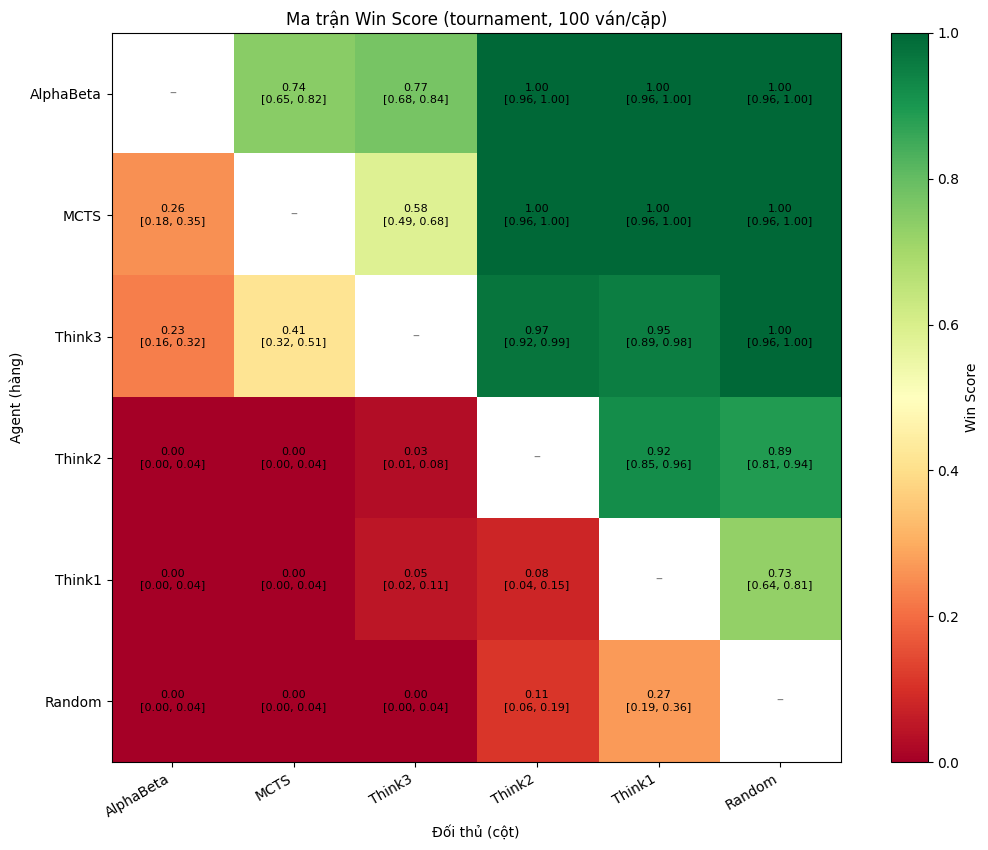

,agent1,agent2,n,wins,draws,losses,score,ci_lo,ci_hi,forfeits
0,Random,Think1,100,27,0,73,0.270,0.193,0.364,0
1,Random,Think2,100,11,0,89,0.110,0.063,0.186,0
2,Random,Think3,100,0,0,100,0.000,0.000,0.037,0
3,Random,AlphaBeta,100,0,0,100,0.000,0.000,0.037,0
4,Random,MCTS,100,0,0,100,0.000,0.000,0.037,0
5,Think1,Think2,100,8,0,92,0.080,0.041,0.150,0
6,Think1,Think3,100,5,0,95,0.050,0.022,0.112,0
7,Think1,AlphaBeta,100,0,0,100,0.000,0.000,0.037,0
8,Think1,MCTS,100,0,0,100,0.000,0.000,0.037,0
9,Think2,Think3,100,2,2,96,0.030,0.010,0.085,0


In [31]:
def plot_matrix(pt, title, fname):
    if pt.empty:
        return
    totals = defaultdict(float)
    for _, r in pt.iterrows():
        totals[r.agent1] += r.score
        totals[r.agent2] += 1 - r.score
    names = sorted(totals, key=totals.get, reverse=True)
    idx = {n: i for i, n in enumerate(names)}
    k = len(names)
    M = np.full((k, k), np.nan)
    T = [[""] * k for _ in range(k)]
    for _, r in pt.iterrows():
        i, j = idx[r.agent1], idx[r.agent2]
        M[i, j], M[j, i] = r.score, 1 - r.score
        T[i][j] = f"{r.score:.2f}\n[{r.ci_lo:.2f}, {r.ci_hi:.2f}]"
        T[j][i] = f"{1 - r.score:.2f}\n[{1 - r.ci_hi:.2f}, {1 - r.ci_lo:.2f}]"
    fig, ax = plt.subplots(figsize=(1.35 * k + 3, 1.1 * k + 2))
    im = ax.imshow(M, cmap="RdYlGn", vmin=0, vmax=1)
    ax.set_xticks(range(k), names, rotation=30, ha="right")
    ax.set_yticks(range(k), names)
    for i in range(k):
        for j in range(k):
            if i != j and T[i][j]:
                ax.text(j, i, T[i][j], ha="center", va="center", fontsize=8)
            elif i == j:
                ax.text(j, i, "–", ha="center", va="center", color="gray")
    ax.set_title(title)
    ax.set_xlabel("Đối thủ (cột)")
    ax.set_ylabel("Agent (hàng)")
    fig.colorbar(im, ax=ax, label="Win Score")
    fig.tight_layout()
    savefig(fig, fname)
    plt.show()


PAIR_TABLES = {}
for label, recs in RUNS.items():
    if not recs:
        continue
    PAIR_TABLES[label] = pair_table(recs)
    n_pair = PAIR_TABLES[label]["n"].unique()
    plot_matrix(PAIR_TABLES[label],
                f"Ma trận Win Score ({label}, {', '.join(map(str, n_pair))} ván/cặp)",
                f"fig4_winscore_matrix_{label}.png")
    display(PAIR_TABLES[label].round(3))

## 2. Thắng / hòa / thua theo cặp

đã lưu d:\HK1_3Y\TTNTNC-GameAI-nhom11\results\figures\fig4_wdl_tournament.png


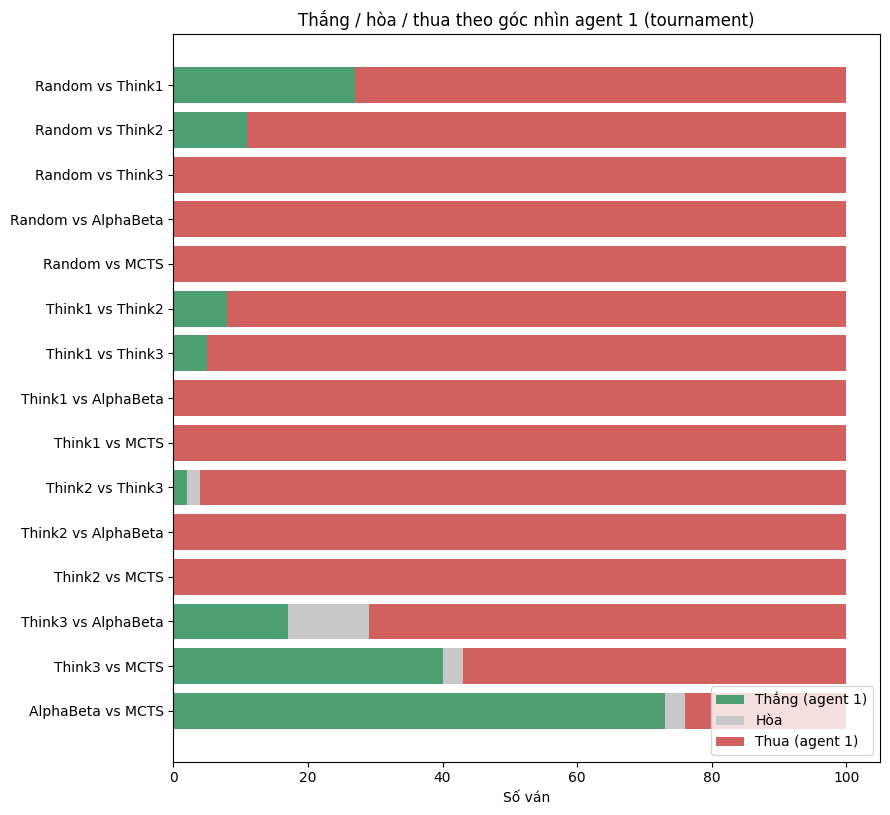

In [32]:
for label, pt in PAIR_TABLES.items():
    labels = [f"{a} vs {b}" for a, b in zip(pt.agent1, pt.agent2)]
    fig, ax = plt.subplots(figsize=(9, 0.45 * len(pt) + 1.5))
    y = np.arange(len(pt))
    ax.barh(y, pt.wins, label="Thắng (agent 1)", color="#4c9f70")
    ax.barh(y, pt.draws, left=pt.wins, label="Hòa", color="#c8c8c8")
    ax.barh(y, pt.losses, left=pt.wins + pt.draws, label="Thua (agent 1)", color="#d1605e")
    ax.set_yticks(y, labels)
    ax.invert_yaxis()
    ax.set_xlabel("Số ván")
    ax.set_title(f"Thắng / hòa / thua theo góc nhìn agent 1 ({label})")
    ax.legend(loc="lower right")
    fig.tight_layout()
    savefig(fig, f"fig4_wdl_{label}.png")
    plt.show()

## 3. Độ trễ theo từng nước

Gom **mọi nước đi** của agent trong các ván rồi tính trung bình và p95 (không tính theo ván).
Lưu ý: nếu giải chạy nhiều tiến trình song song thì độ trễ chịu ảnh hưởng của tải CPU.

── tournament


,moves,avg_ms,p95_ms,max_ms
agent,,,,
AlphaBeta,4174,50.11,149.82,624.97
MCTS,4561,29.25,64.37,347.52
Random,2794,0.02,0.02,5.54
Think1,2772,0.14,0.32,7.41
Think2,4162,0.66,1.61,39.03
Think3,4871,0.81,2.31,59.46


đã lưu d:\HK1_3Y\TTNTNC-GameAI-nhom11\results\figures\fig4_latency.png


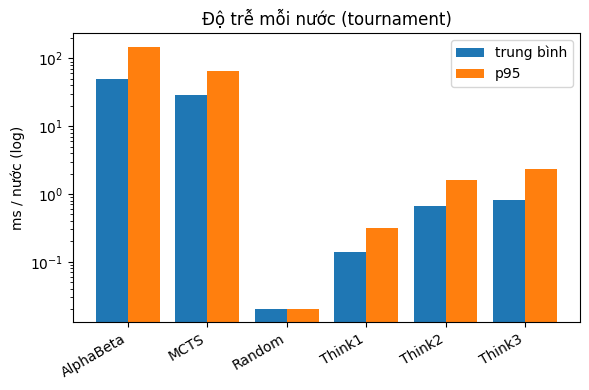

In [33]:
MOVES = {label: moves_df(recs) for label, recs in RUNS.items() if recs}
LAT = {}
for label, mv in MOVES.items():
    g = mv.groupby("agent")["ms"]
    LAT[label] = pd.DataFrame({"moves": g.size(), "avg_ms": g.mean(),
                               "p95_ms": g.quantile(0.95), "max_ms": g.max()}).round(2)
    print(f"── {label}")
    display(LAT[label])

if LAT:
    fig, axes = plt.subplots(1, len(LAT), figsize=(6 * len(LAT), 4), squeeze=False)
    for ax, (label, t) in zip(axes[0], LAT.items()):
        x = np.arange(len(t))
        ax.bar(x - 0.2, t.avg_ms, 0.4, label="trung bình")
        ax.bar(x + 0.2, t.p95_ms, 0.4, label="p95")
        ax.set_xticks(x, t.index, rotation=30, ha="right")
        ax.set_yscale("log")
        ax.set_ylabel("ms / nước (log)")
        ax.set_title(f"Độ trễ mỗi nước ({label})")
        ax.legend()
    fig.tight_layout()
    savefig(fig, "fig4_latency.png")
    plt.show()

## 4. Nút/giây và mô phỏng/giây

Tính gộp: tổng số nút (hoặc mô phỏng) chia tổng thời gian của các nước của agent đó.
Chỉ Alpha-Beta có `nodes`/`depth`, chỉ MCTS có `sims`.

In [34]:
THR = {}
for label, mv in MOVES.items():
    rows = []
    for col, unit in (("nodes", "nút/s"), ("sims", "mô phỏng/s")):
        if col not in mv:
            continue
        sub = mv[mv[col].notna() & (mv["ms"] > 0)]
        for agent, g in sub.groupby("agent"):
            per_move = g[col] / g["ms"] * 1000
            rows.append({"agent": agent, "đơn vị": unit, "nước": len(g),
                         "tổng (gộp)": g[col].sum() / g["ms"].sum() * 1000,
                         "trung vị mỗi nước": per_move.median(),
                         f"{col} TB/nước": g[col].mean()})
    THR[label] = pd.DataFrame(rows).round(1)
    print(f"── {label}")
    display(THR[label])

if "depth" in next(iter(MOVES.values()), pd.DataFrame()):
    for label, mv in MOVES.items():
        d = mv[mv["depth"].notna()].groupby("agent")["depth"].agg(["mean", "median", "max"]).round(2)
        print(f"Độ sâu Alpha-Beta đạt được ({label})")
        display(d)

── tournament


,agent,đơn vị,nước,tổng (gộp),trung vị mỗi nước,nodes TB/nước,sims TB/nước
0,AlphaBeta,nút/s,4174,22265.4,28236.0,1115.8,NaN
1,MCTS,mô phỏng/s,4561,6838.0,7526.2,NaN,200.0


Độ sâu Alpha-Beta đạt được (tournament)


,mean,median,max
agent,,,
AlphaBeta,4.47,5.0,5.0


## 5. Đi trước và đi sau

tournament: điểm trung bình của bên đi trước (mọi cặp) = 0.500
đã lưu d:\HK1_3Y\TTNTNC-GameAI-nhom11\results\figures\fig4_first_second_tournament.png


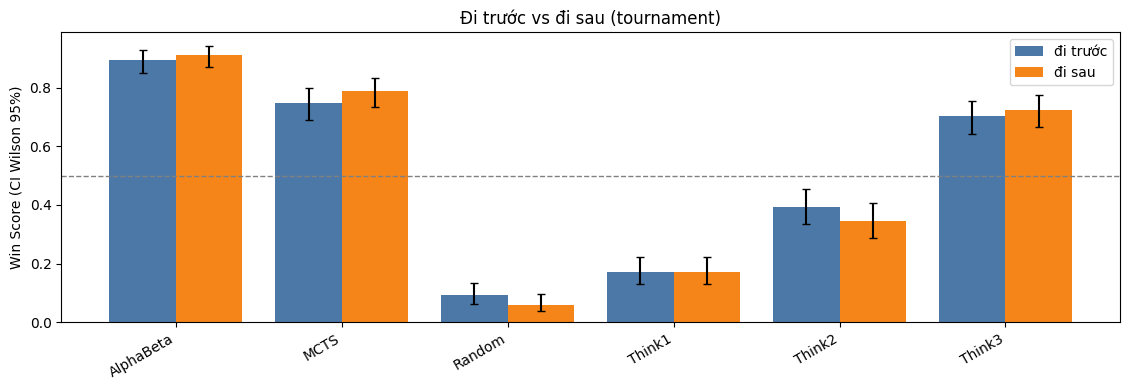

,agent,went_first,n,score,ci_lo,ci_hi
0,AlphaBeta,False,250,0.912,0.870,0.941
1,AlphaBeta,True,250,0.894,0.850,0.926
2,MCTS,False,250,0.788,0.733,0.834
3,MCTS,True,250,0.748,0.691,0.798
4,Random,False,250,0.060,0.037,0.097
5,Random,True,250,0.092,0.062,0.134
6,Think1,False,250,0.172,0.130,0.224
7,Think1,True,250,0.172,0.130,0.224
8,Think2,False,250,0.344,0.288,0.405
9,Think2,True,250,0.392,0.334,0.454


In [35]:
FS = {}
for label, recs in RUNS.items():
    if not recs:
        continue
    av = agent_view(recs)
    rows = []
    for (agent, first), g in av.groupby(["agent", "went_first"]):
        lo, hi = wilson_ci(g.score.sum(), len(g))
        rows.append(dict(agent=agent, went_first=first, n=len(g),
                         score=g.score.mean(), ci_lo=lo, ci_hi=hi))
    fs = pd.DataFrame(rows)
    FS[label] = fs
    first_adv = av[av.went_first].score.mean()
    print(f"{label}: điểm trung bình của bên đi trước (mọi cặp) = {first_adv:.3f}")

    agents = sorted(fs.agent.unique())
    fig, ax = plt.subplots(figsize=(1.4 * len(agents) + 3, 4))
    x = np.arange(len(agents))
    for off, first, name, color in ((-0.2, True, "đi trước", "#4c78a8"),
                                    (0.2, False, "đi sau", "#f58518")):
        s = fs[fs.went_first == first].set_index("agent").reindex(agents)
        ax.bar(x + off, s.score, 0.4, label=name, color=color,
               yerr=[(s.score - s.ci_lo).clip(lower=0), (s.ci_hi - s.score).clip(lower=0)], capsize=3)
    ax.axhline(0.5, color="gray", ls="--", lw=1)
    ax.set_xticks(x, agents, rotation=30, ha="right")
    ax.set_ylabel("Win Score (CI Wilson 95%)")
    ax.set_title(f"Đi trước vs đi sau ({label})")
    ax.legend()
    fig.tight_layout()
    savefig(fig, f"fig4_first_second_{label}.png")
    plt.show()
    display(fs.round(3))

## 6. RQ1: Alpha-Beta vs MCTS theo ngân sách thời gian

Mức ngân sách lấy từ `budget_ms` trong `spec` của từng ván (nên không phụ thuộc tên file).
Điểm tính theo góc nhìn Alpha-Beta.

Đã load 100 ván từ d:\HK1_3Y\TTNTNC-GameAI-nhom11\logs\rq1_200ms_games.jsonl
Đã load 100 ván từ d:\HK1_3Y\TTNTNC-GameAI-nhom11\logs\rq1_1000ms_games.jsonl


,budget_ms,n,AB thắng,hòa,AB thua,AB score,ci_lo,ci_hi,AB độ sâu TB,MCTS mô phỏng TB,AB p95 ms,MCTS p95 ms
0,200,100,48,2,50,0.490,0.394,0.587,5.716,12119.194,200.022,200.234
1,1000,100,50,9,41,0.545,0.448,0.639,5.893,74126.920,259.784,1000.240


đã lưu d:\HK1_3Y\TTNTNC-GameAI-nhom11\results\figures\fig4_rq1_budget.png


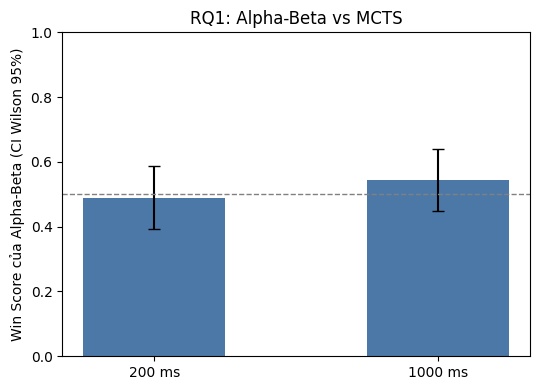

In [36]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def spec_budget(record):
    # Thử tìm budget_ms trong spec1 hoặc spec2
    for spec_key in ["spec1", "spec2"]:
        if spec_key in record and "kwargs" in record[spec_key]:
            if "budget_ms" in record[spec_key]["kwargs"]:
                return record[spec_key]["kwargs"]["budget_ms"]
    # Nếu không thấy, thử tìm trực tiếp ở ngoài cùng
    return record.get("budget_ms", record.get("time_limit", None))
# 1. Hàm tự định nghĩa moves_df an toàn để trích xuất thông tin từ danh sách moves của từng ván
def moves_df(rs):
    rows = []
    for r in rs:
        game_id = r.get("game_id")
        for m in r.get("moves", []):
            rows.append({
                "game_id": game_id,
                "agent": m.get("agent"),
                "depth": m.get("depth", np.nan),
                "sims": m.get("sims", np.nan),
                "ms": m.get("ms", np.nan)
            })
    return pd.DataFrame(rows)

# 2. Xử lý chính cho RQ1
rq1 = []
for p in RQ1_LOGS:
    if os.path.exists(p):
        data = load_jsonl(p)
        rq1 += data
        print(f"Đã load {len(data)} ván từ {p}")
    else:
        print(f"❌ KHÔNG TÌM THẤY FILE: {p}")

if not rq1:
    print("CẢNH BÁO: Không có dữ liệu RQ1 nào được load. Hãy kiểm tra lại đường dẫn!")
else:
    # Tiến hành lọc trùng lặp và lọc AB vs MCTS như cũ
    rq1 = list({
    (r["game_id"], spec_budget(r)): r 
    for r in rq1 
    if isinstance(r, dict) and "game_id" in r
}.values())
    is_ab = lambda n: n.lower().startswith("alphabeta")

    rq1 = [
        r for r in rq1
        if isinstance(r, dict)
        and "pair" in r
        and any(is_ab(str(n)) for n in r["pair"])
        and any(str(n).lower().startswith("mcts") for n in r["pair"])
    ]

    RQ1 = pd.DataFrame()
    if rq1:
        rows = []
        for budget in sorted({spec_budget(r) for r in rq1}, key=lambda b: (b is None, b)):
            rs = [r for r in rq1 if spec_budget(r) == budget]
            if not rs:
                continue
            sc, w, d, l = [], 0, 0, 0
            for r in rs:
                k = 0 if is_ab(r["pair"][0]) else 1
                s = r["score1"] if k == 0 else 1 - r["score1"]
                sc.append(s)
                w += (s == 1)
                d += (s == 0.5)
                l += (s == 0)
                
            n = len(rs)
            lo, hi = wilson_ci(sum(sc), n) if 'wilson_ci' in globals() else (0, 0)
            
            mv = moves_df(rs)
            
            ab_names = [n for n in rs[0]["pair"] if is_ab(n)]
            mc_names = [n for n in rs[0]["pair"] if not is_ab(n)]
            
            ab_name = ab_names[0] if ab_names else "alphabeta"
            mc_name = mc_names[0] if mc_names else "mcts"
            
            ab = mv[mv.agent == ab_name] if not mv.empty else pd.DataFrame()
            mc = mv[mv.agent == mc_name] if not mv.empty else pd.DataFrame()
            
            rows.append({
                "budget_ms": budget, 
                "n": n, 
                "AB thắng": w, 
                "hòa": d, 
                "AB thua": l,
                "AB score": np.mean(sc) if sc else 0, 
                "ci_lo": lo, 
                "ci_hi": hi,
                "AB độ sâu TB": ab["depth"].mean() if not ab.empty and "depth" in ab else np.nan,
                "MCTS mô phỏng TB": mc["sims"].mean() if not mc.empty and "sims" in mc else np.nan,
                "AB p95 ms": ab.ms.quantile(0.95) if not ab.empty and "ms" in ab and ab.ms.notna().any() else np.nan, 
                "MCTS p95 ms": mc.ms.quantile(0.95) if not mc.empty and "ms" in mc and mc.ms.notna().any() else np.nan
            })
            
        RQ1 = pd.DataFrame(rows)
        if not RQ1.empty:
            display(RQ1.round(3))

            fig, ax = plt.subplots(figsize=(5.5, 4))
            x = np.arange(len(RQ1))
            ax.bar(x, RQ1["AB score"], 0.5, color="#4c78a8",
                   yerr=[(RQ1["AB score"] - RQ1.ci_lo).clip(lower=0), (RQ1.ci_hi - RQ1["AB score"]).clip(lower=0)], capsize=4)
            ax.axhline(0.5, color="gray", ls="--", lw=1)
            ax.set_xticks(x, [f"{b:g} ms" if b is not None else "Unknown" for b in RQ1.budget_ms])
            ax.set_ylim(0, 1)
            ax.set_ylabel("Win Score của Alpha-Beta (CI Wilson 95%)")
            ax.set_title("RQ1: Alpha-Beta vs MCTS")
            fig.tight_layout()
            if 'savefig' in globals():
                savefig(fig, "fig4_rq1_budget.png")
            plt.show()

## 7. Ablation A1: cắt tỉa và sắp xếp nước (Alpha-Beta)

Ablation: seed=42, đối thủ=Think2, ván/cấu hình=100, máy=Windows-10-10.0.19045-SP0


,cấu hình,depth,nút TB,nút trung vị,ms/nước TB,ms/nước p95
0,"prune=on, order=on",4,344.3,347.5,11.38,21.33
1,"prune=on, order=off",4,605.7,507.5,12.86,23.69
2,"prune=off, order=on",4,2155.1,2436.5,49.40,70.27
3,"prune=off, order=off",4,2155.1,2436.5,69.82,131.86


đã lưu d:\HK1_3Y\TTNTNC-GameAI-nhom11\results\figures\fig4_a1_cost.png


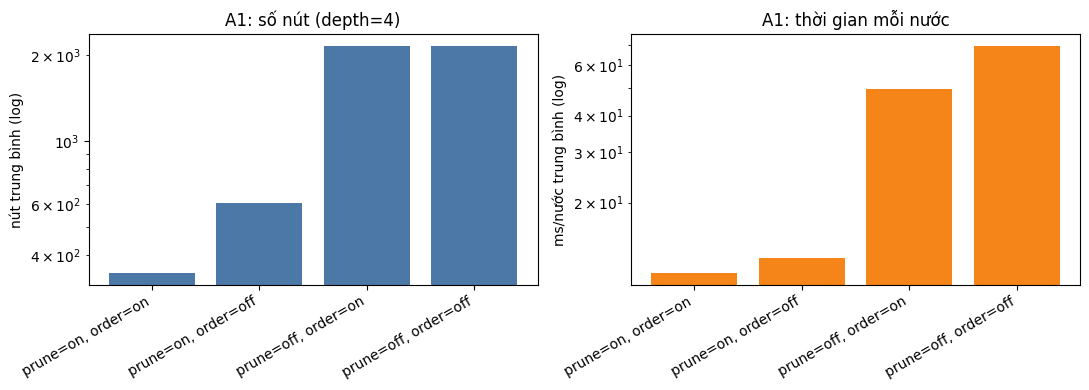

,cấu hình,budget_ms,độ sâu TB,độ sâu min,độ sâu max,tỷ lệ hết giờ
0,"prune=on, order=on",50,5.50,4.0,8.0,1.0
1,"prune=on, order=on",200,6.75,5.0,10.0,1.0
2,"prune=on, order=off",50,4.75,4.0,6.0,1.0
3,"prune=on, order=off",200,6.00,5.0,8.0,1.0
4,"prune=off, order=on",50,3.30,3.0,5.0,1.0
5,"prune=off, order=on",200,4.15,4.0,5.0,1.0
6,"prune=off, order=off",50,3.25,3.0,5.0,1.0
7,"prune=off, order=off",200,4.25,4.0,6.0,1.0


đã lưu d:\HK1_3Y\TTNTNC-GameAI-nhom11\results\figures\fig4_a1_depth_budget.png


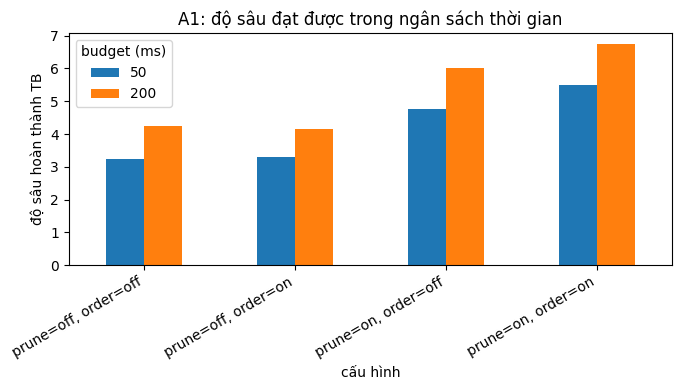

,cấu hình,ván,thắng,hòa,thua,score,ci_lo,ci_hi,p95 ms/nước
0,"prune=on, order=on",100,100,0,0,1.0,0.963,1.0,18.916
1,"prune=on, order=off",100,100,0,0,1.0,0.963,1.0,22.083
2,"prune=off, order=on",100,100,0,0,1.0,0.963,1.0,68.322
3,"prune=off, order=off",100,100,0,0,1.0,0.963,1.0,69.974


đã lưu d:\HK1_3Y\TTNTNC-GameAI-nhom11\results\figures\fig4_a1_match.png


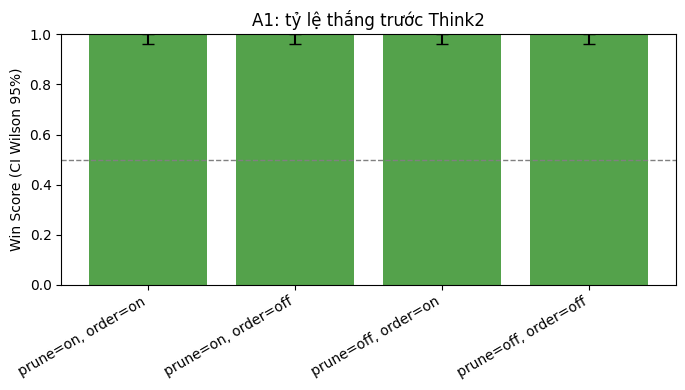

In [37]:
abl = load_jsonl(ABLATION_LOG)
by_kind = defaultdict(list)
for r in abl:
    by_kind[r["kind"]].append(r)

meta = by_kind["meta"][0] if by_kind["meta"] else {}
if meta:
    print(f"Ablation: seed={meta.get('seed')}, đối thủ={meta.get('opponent')}, "
          f"ván/cấu hình={meta.get('games')}, máy={meta.get('machine')}")
    if meta.get("reduced"):
        print("⚠️ ", meta.get("note"))


def a1_label(c):
    return f"prune={'on' if c['use_pruning'] else 'off'}, order={'on' if c['use_ordering'] else 'off'}"


# A1: số nút và thời gian mỗi nước
cost = pd.DataFrame([{
    "cấu hình": a1_label(r["config"]), "depth": r["config"]["depth"],
    "nút TB": r["nodes"]["mean"], "nút trung vị": r["nodes"]["median"],
    "ms/nước TB": r["ms_per_move"]["mean"], "ms/nước p95": r["ms_per_move"]["p95"],
} for r in by_kind["A1_cost"]])

if not cost.empty:
    display(cost.round(2))
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].bar(cost["cấu hình"], cost["nút TB"], color="#4c78a8")
    axes[0].set_yscale("log"); axes[0].set_ylabel("nút trung bình (log)")
    axes[0].set_title(f"A1: số nút (depth={cost.depth.iloc[0]})")
    axes[1].bar(cost["cấu hình"], cost["ms/nước TB"], color="#f58518")
    axes[1].set_yscale("log"); axes[1].set_ylabel("ms/nước trung bình (log)")
    axes[1].set_title("A1: thời gian mỗi nước")
    for ax in axes:
        ax.tick_params(axis="x", rotation=30)
        plt.setp(ax.get_xticklabels(), ha="right")
    fig.tight_layout()
    savefig(fig, "fig4_a1_cost.png")
    plt.show()

# A1: độ sâu đạt được trong budget
bud = pd.DataFrame([{
    "cấu hình": a1_label(r["config"]), "budget_ms": r["config"]["budget_ms"],
    "độ sâu TB": r["depth_reached"]["mean"], "độ sâu min": r["depth_reached"]["min"],
    "độ sâu max": r["depth_reached"]["max"], "tỷ lệ hết giờ": r["timed_out_rate"],
} for r in by_kind["A1_budget"]])

if not bud.empty:
    display(bud.round(2))
    p = bud.pivot(index="cấu hình", columns="budget_ms", values="độ sâu TB")
    ax = p.plot.bar(figsize=(7, 4), rot=30)
    ax.set_ylabel("độ sâu hoàn thành TB")
    ax.set_title("A1: độ sâu đạt được trong ngân sách thời gian")
    ax.legend(title="budget (ms)")
    plt.setp(ax.get_xticklabels(), ha="right")
    ax.figure.tight_layout()
    savefig(ax.figure, "fig4_a1_depth_budget.png")
    plt.show()

# A1: tỷ lệ thắng trước đối thủ cố định
m1 = pd.DataFrame([{
    "cấu hình": a1_label(r["config"]), "ván": r["games"], "thắng": r["wins"],
    "hòa": r["draws"], "thua": r["losses"], "score": r["score"],
    "ci_lo": r["wilson_ci"][0], "ci_hi": r["wilson_ci"][1],
    "p95 ms/nước": (r["latency_ms"] or {}).get("p95_ms"),
} for r in by_kind["A1_match"]])

if not m1.empty:
    display(m1.round(3))
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.bar(m1["cấu hình"], m1.score, color="#54a24b",
           yerr=[(m1.score - m1.ci_lo).clip(lower=0), (m1.ci_hi - m1.score).clip(lower=0)], capsize=4)
    ax.axhline(0.5, color="gray", ls="--", lw=1)
    ax.set_ylim(0, 1)
    ax.set_ylabel("Win Score (CI Wilson 95%)")
    ax.set_title(f"A1: tỷ lệ thắng trước {meta.get('opponent', 'đối thủ cố định')}")
    ax.tick_params(axis="x", rotation=30)
    plt.setp(ax.get_xticklabels(), ha="right")
    fig.tight_layout()
    savefig(fig, "fig4_a1_match.png")
    plt.show()

## 8. Ablation A2: MCTS (`n_simulations` × `c`)

,n_simulations,c,ván,thắng,hòa,thua,score,ci_lo,ci_hi,avg ms/nước,p95 ms/nước
0,50,0.500,100,69,1,30,0.695,0.599,0.777,3.830,7.097
1,50,1.000,100,79,0,21,0.790,0.700,0.858,3.613,6.386
2,50,1.414,100,75,1,24,0.755,0.662,0.829,4.070,7.235
3,50,2.000,100,70,1,29,0.705,0.609,0.786,3.815,6.725
4,100,0.500,100,81,0,19,0.810,0.722,0.875,6.902,11.961
5,100,1.000,100,95,0,5,0.950,0.888,0.978,7.132,12.679
6,100,1.414,100,92,0,8,0.920,0.850,0.959,7.229,11.975
7,100,2.000,100,88,0,12,0.880,0.802,0.930,7.921,14.643
8,200,0.500,100,99,0,1,0.990,0.946,0.998,13.929,24.669
9,200,1.000,100,100,0,0,1.000,0.963,1.000,14.515,23.581


đã lưu d:\HK1_3Y\TTNTNC-GameAI-nhom11\results\figures\fig4_a2_mcts.png


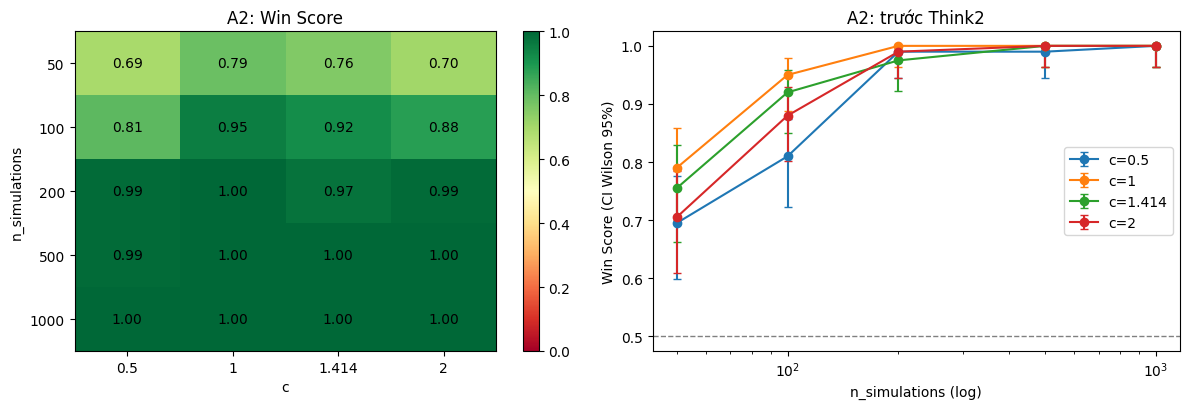

In [38]:
a2 = pd.DataFrame([{
    "n_simulations": r["config"]["n_simulations"], "c": r["config"]["c"],
    "ván": r["games"], "thắng": r["wins"], "hòa": r["draws"], "thua": r["losses"],
    "score": r["score"], "ci_lo": r["wilson_ci"][0], "ci_hi": r["wilson_ci"][1],
    "avg ms/nước": (r["latency_ms"] or {}).get("avg_ms"),
    "p95 ms/nước": (r["latency_ms"] or {}).get("p95_ms"),
} for r in by_kind["A2_match"]])

if not a2.empty:
    display(a2.round(3))
    piv = a2.pivot(index="n_simulations", columns="c", values="score")
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

    ax = axes[0]
    im = ax.imshow(piv.values, cmap="RdYlGn", vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(piv.shape[1]), [f"{c:g}" for c in piv.columns])
    ax.set_yticks(range(piv.shape[0]), piv.index)
    for i in range(piv.shape[0]):
        for j in range(piv.shape[1]):
            if not np.isnan(piv.values[i, j]):
                ax.text(j, i, f"{piv.values[i, j]:.2f}", ha="center", va="center")
    ax.set_xlabel("c"); ax.set_ylabel("n_simulations")
    ax.set_title("A2: Win Score")
    fig.colorbar(im, ax=ax)

    ax = axes[1]
    for c, g in a2.groupby("c"):
        g = g.sort_values("n_simulations")
        ax.errorbar(g.n_simulations, g.score,
                    yerr=[(g.score - g.ci_lo).clip(lower=0), (g.ci_hi - g.score).clip(lower=0)], marker="o",
                    capsize=3, label=f"c={c:g}")
    ax.axhline(0.5, color="gray", ls="--", lw=1)
    ax.set_xscale("log")
    ax.set_xlabel("n_simulations (log)"); ax.set_ylabel("Win Score (CI Wilson 95%)")
    ax.set_title(f"A2: trước {meta.get('opponent', 'đối thủ cố định')}")
    ax.legend()
    fig.tight_layout()
    savefig(fig, "fig4_a2_mcts.png")
    plt.show()

## 9. Xuất bảng tóm tắt (nhẹ, đưa lên GitHub)

Log thô lớn để trên Drive; chỉ các file `summary_*.csv` này được commit (nhớ kiểm tra dưới 50 MB).

In [39]:
outputs = {}
for label, pt in PAIR_TABLES.items():
    outputs[f"summary_pairs_{label}.csv"] = pt
for label, t in LAT.items():
    outputs[f"summary_latency_{label}.csv"] = t.reset_index()
for label, t in THR.items():
    outputs[f"summary_throughput_{label}.csv"] = t
for label, t in FS.items():
    outputs[f"summary_first_second_{label}.csv"] = t
for name, df in (("summary_rq1.csv", RQ1), ("summary_a1_cost.csv", cost),
                 ("summary_a1_budget.csv", bud), ("summary_a1_match.csv", m1),
                 ("summary_a2.csv", a2)):
    outputs[name] = df

for name, df in outputs.items():
    if df is not None and len(df):
        df.to_csv(LOG_DIR / name, index=False, encoding="utf-8")
        print(f"đã ghi logs/{name} ({len(df)} dòng)")

total_mb = sum(p.stat().st_size for p in LOG_DIR.glob("summary_*.csv")) / 1e6
print(f"\nTổng dung lượng summary_*.csv: {total_mb:.2f} MB")

đã ghi logs/summary_pairs_tournament.csv (15 dòng)
đã ghi logs/summary_latency_tournament.csv (6 dòng)
đã ghi logs/summary_throughput_tournament.csv (2 dòng)
đã ghi logs/summary_first_second_tournament.csv (12 dòng)
đã ghi logs/summary_rq1.csv (2 dòng)
đã ghi logs/summary_a1_cost.csv (4 dòng)
đã ghi logs/summary_a1_budget.csv (8 dòng)
đã ghi logs/summary_a1_match.csv (4 dòng)
đã ghi logs/summary_a2.csv (20 dòng)

Tổng dung lượng summary_*.csv: 0.00 MB
